# 4차 실험: 임계값 조정과 앙상블

| 항목 | 내용 |
|---|---|
| 목적 | 1~3차에서 만든 모델들의 OOF 예측을 조합하고 임계값을 조정해 F1을 더 올린다 (재학습 없음) |
| 재료 | 1차 9개 모델, 2차 변형별 모델, 3차 튜닝 모델의 OOF 예측 확률 — 모두 같은 개발 세트 6,400행·같은 fold |
| 평가 | 모든 선택(임계값, 가중치, 모델 고르기)을 fold 안에서 한다: fold k의 점수는 나머지 4개 fold의 OOF로만 정한 규칙을 fold k에 적용해서 잰다 |
| 비교 | 3차 최고 단일 모델(임계값 0.5)과 fold별 짝지은 보정 t-검정 |

| 방법 | 내용 |
|---|---|
| 임계값 조정 | 나머지 fold에서 F1이 최대가 되는 임계값을 골라 적용 |
| 단순 평균 | 3차 튜닝 모델 3개의 확률 평균 |
| 스태킹 | 각 모델 예측(logit)을 입력으로 하는 로지스틱 회귀가 가중치를 학습 |
| 탐욕적 선택 (Caruana) | 후보 중 F1을 가장 올리는 모델을 하나씩 더해 가며(중복 허용) 평균 — 나머지 fold에서 고름 |

참고: 스태킹·탐욕적 선택에서 fold j의 OOF를 만든 모델은 fold k 데이터로도 학습했다. 이 때문에 아주 약간 낙관적일 수 있으며, 일반적으로 허용되는 수준이다. 최종 확인은 테스트 세트로 한다.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from scipy import stats

HERE = Path.cwd(); M = HERE.parent
sys.path.insert(0, str(M / "common"))
from preprocess import preprocess_train
from evaluate import load_splits

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
RES = HERE / "results"; RES.mkdir(exist_ok=True)

## 1. OOF 예측 모으기

In [2]:
df, X, y, groups = preprocess_train(M.parent / "train.csv"); df = load_splits(df)
dev = (df["set"] == "dev").values
yd = y[dev]; smi = df.loc[dev, "SMILES"].values
folds = df.loc[dev, ["fold_r0", "fold_r1"]].reset_index(drop=True)

def read_oof(path, prefix):
    o = pd.read_csv(path); assert (o["SMILES"].values == smi).all()
    out = {}
    for c in o.columns:
        if "|r" not in c: continue
        name, r = c.rsplit("|", 1)
        out.setdefault(prefix + name, {})[r] = o[c].values
    return out

pool = {}
pool.update(read_oof(M / "exp01_model_comparison/results/oof_predictions.csv", "1차:"))
pool.update({k: v for k, v in read_oof(M / "exp02_feature_variants/results/oof_predictions.csv", "2차:").items() if not k.startswith("2차:base|")})
pool.update(read_oof(M / "exp03_tuning/results/oof_predictions.csv", "3차:"))
pool = {k: v for k, v in pool.items() if set(v) == {"r0", "r1"}}
NONPROB = [k for k in pool if "SVM" in k]          # 확률이 아닌 점수 (평균에는 제외, 스태킹에는 사용)
print("후보 모델 수:", len(pool))

def f1_at(p, t=0.5): return f1_score(yd_, p >= t)
single = pd.DataFrame({k: [np.mean([f1_score(yd, v[r] >= .5) for r in ("r0", "r1")]),
                           np.mean([roc_auc_score(yd, v[r]) for r in ("r0", "r1")])] for k, v in pool.items()},
                      index=["F1@0.5", "AUC"]).T.sort_values("F1@0.5", ascending=False)
display(single.head(15).round(4))
tuned = [k for k in pool if k.startswith("3차:")]
BEST = max(tuned, key=lambda k: single.loc[k, "F1@0.5"])
print("기준(3차 최고 단일 모델):", BEST)

후보 모델 수: 33


,F1@0.5,AUC
3차:tuned|XGBoost,0.8218,0.8822
3차:tuned|LightGBM,0.8215,0.8830
3차:tuned|RandomForest,0.8211,0.8770
2차:count_chiral|RandomForest,0.8191,0.8764
2차:+maccs|RandomForest,0.8190,0.8746
2차:+ptfp|LightGBM,0.8185,0.8787
2차:+ap_tt|LightGBM,0.8180,0.8785
2차:+maccs|LightGBM,0.8178,0.8772
1차:RandomForest,0.8177,0.8736
2차:+mordred|XGBoost,0.8165,0.8733


기준(3차 최고 단일 모델): 3차:tuned|XGBoost


## 2. fold 안에서 규칙을 정하는 평가 함수

In [3]:
ths = np.round(np.arange(0.30, 0.701, 0.01), 2)
def best_thr(yv, p):
    f = [f1_score(yv, p >= t) for t in ths]; return ths[int(np.argmax(f))]
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def evaluate(method):
    """method(r, tr_mask, va_mask) -> (검증 fold 확률, 학습 fold 확률). 반환: fold별 F1(0.5), F1(fold 안 임계값), 임계값"""
    rows = []
    for ri, r in enumerate(("r0", "r1")):
        f = folds[f"fold_r{ri}"].values
        for k in range(5):
            tr, va = f != k, f == k
            p_va, p_tr = method(r, tr, va)
            t = best_thr(yd[tr], p_tr)
            rows.append(dict(repeat=ri, fold=k, f1=f1_score(yd[va], p_va >= .5), f1_thr=f1_score(yd[va], p_va >= t),
                             thr=t, auc=roc_auc_score(yd[va], p_va)))
    return pd.DataFrame(rows)

def m_single(name):
    return lambda r, tr, va: (pool[name][r][va], pool[name][r][tr])
def m_mean(names):
    return lambda r, tr, va: (np.mean([pool[n][r][va] for n in names], 0), np.mean([pool[n][r][tr] for n in names], 0))
def m_stack(names, C=1.0):
    def f(r, tr, va):
        Z = np.column_stack([logit(pool[n][r]) for n in names])
        lr = LogisticRegression(C=C, max_iter=2000).fit(Z[tr], yd[tr])
        return lr.predict_proba(Z[va])[:, 1], lr.predict_proba(Z[tr])[:, 1]
    return f
def m_greedy(cands, n_iter=15):
    def f(r, tr, va):
        chosen, cur = [], None
        for _ in range(n_iter):
            best, bf = None, -1
            for c in cands:
                p = pool[c][r][tr] if cur is None else (cur * len(chosen) + pool[c][r][tr]) / (len(chosen) + 1)
                s = f1_score(yd[tr], p >= .5)
                if s > bf: best, bf = c, s
            chosen.append(best)
            cur = np.mean([pool[c][r][tr] for c in chosen], 0)
        f.last = chosen
        return np.mean([pool[c][r][va] for c in chosen], 0), cur
    return f

## 3. 방법별 평가

In [4]:
prob_all = [k for k in pool if k not in NONPROB]
top_prob = single.loc[prob_all].sort_values("F1@0.5", ascending=False).index[:12].tolist()
methods = {
    f"단일: {BEST}": m_single(BEST),
    "평균: 3차 튜닝 3개": m_mean(tuned),
    "스태킹: 3차 튜닝 3개": m_stack(tuned),
    "스태킹: 전체 후보": m_stack(list(pool), C=0.1),
    "탐욕적 선택: 상위 12개 후보": m_greedy(top_prob),
}
res = {}
for name, fn in methods.items():
    res[name] = evaluate(fn)
    print(f"{name:40s} F1@0.5 {res[name].f1.mean():.4f} | F1@fold안 임계값 {res[name].f1_thr.mean():.4f} | AUC {res[name].auc.mean():.4f}", flush=True)

base = res[f"단일: {BEST}"]["f1"].values
n_tr, n_va = 5120, 1280
def ptest(d):
    v = d.var(ddof=1); t = d.mean() / np.sqrt((1 / len(d) + n_va / n_tr) * v) if v > 0 else 0
    return 2 * stats.t.sf(abs(t), len(d) - 1)
rows = []
for name, r in res.items():
    for col, lab in (("f1", "임계값 0.5"), ("f1_thr", "fold 안 임계값")):
        d = r[col].values - base
        rows.append((name, lab, r[col].mean(), r[col].std(ddof=0), d.mean(), ptest(d) if name != f"단일: {BEST}" or col != "f1" else np.nan,
                     int((d > 0).sum()), r.thr.median() if col == "f1_thr" else 0.5))
summary = pd.DataFrame(rows, columns=["방법", "임계값", "F1", "F1_std", "기준 대비", "p값", "10 fold 중 개선", "임계값(중앙값)"])
summary.to_csv(RES / "summary.csv", index=False)
display(summary.round(4))

단일: 3차:tuned|XGBoost                     F1@0.5 0.8218 | F1@fold안 임계값 0.8211 | AUC 0.8824


평균: 3차 튜닝 3개                             F1@0.5 0.8236 | F1@fold안 임계값 0.8252 | AUC 0.8843


스태킹: 3차 튜닝 3개                            F1@0.5 0.8225 | F1@fold안 임계값 0.8265 | AUC 0.8844


스태킹: 전체 후보                               F1@0.5 0.8235 | F1@fold안 임계값 0.8282 | AUC 0.8866


탐욕적 선택: 상위 12개 후보                        F1@0.5 0.8235 | F1@fold안 임계값 0.8249 | AUC 0.8851


,방법,임계값,F1,F1_std,기준 대비,p값,10 fold 중 개선,임계값(중앙값)
0,단일: 3차:tuned|XGBoost,임계값 0.5,0.8218,0.0059,0.0000,NaN,0,0.500
1,단일: 3차:tuned|XGBoost,fold 안 임계값,0.8211,0.0065,-0.0007,0.6634,4,0.450
2,평균: 3차 튜닝 3개,임계값 0.5,0.8236,0.0060,0.0018,0.4405,7,0.500
3,평균: 3차 튜닝 3개,fold 안 임계값,0.8252,0.0064,0.0034,0.2541,8,0.400
4,스태킹: 3차 튜닝 3개,임계값 0.5,0.8225,0.0067,0.0007,0.7911,6,0.500
5,스태킹: 3차 튜닝 3개,fold 안 임계값,0.8265,0.0053,0.0047,0.1365,8,0.415
6,스태킹: 전체 후보,임계값 0.5,0.8235,0.0088,0.0016,0.6032,4,0.500
7,스태킹: 전체 후보,fold 안 임계값,0.8282,0.0070,0.0064,0.0818,8,0.425
8,탐욕적 선택: 상위 12개 후보,임계값 0.5,0.8235,0.0087,0.0017,0.6729,6,0.500
9,탐욕적 선택: 상위 12개 후보,fold 안 임계값,0.8249,0.0100,0.0031,0.4276,7,0.495


## 4. 시각화

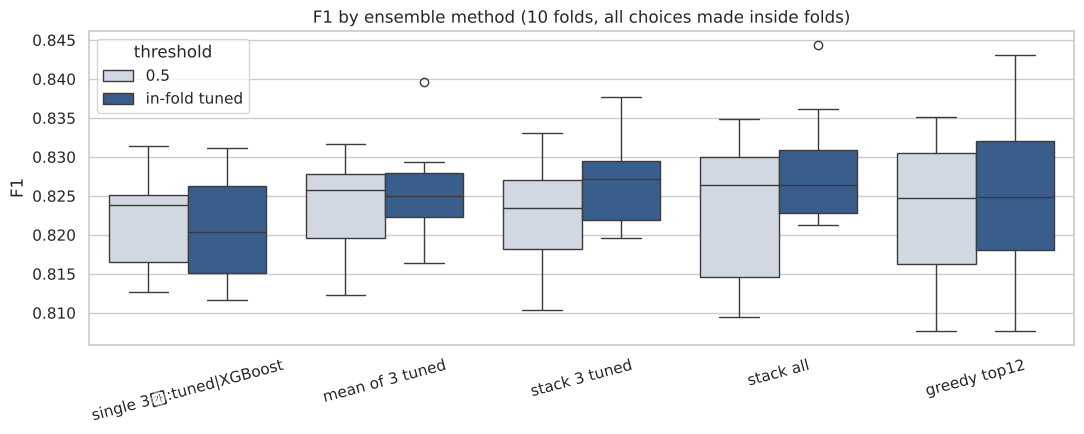

In [5]:
long = pd.concat([r.assign(method=n) for n, r in res.items()])
long = long.melt(id_vars=["method", "repeat", "fold"], value_vars=["f1", "f1_thr"], var_name="threshold", value_name="F1")
long["threshold"] = long.threshold.map({"f1": "0.5", "f1_thr": "in-fold tuned"})
long["method"] = long.method.str.replace("단일: ", "single ").str.replace("평균: 3차 튜닝 3개", "mean of 3 tuned") \
    .str.replace("스태킹: 3차 튜닝 3개", "stack 3 tuned").str.replace("스태킹: 전체 후보", "stack all").str.replace("탐욕적 선택: 상위 12개 후보", "greedy top12")
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=long, x="method", y="F1", hue="threshold", ax=ax, palette=["#cfd8e3", "#2b5d9a"])
ax.set_xlabel(""); ax.set_title("F1 by ensemble method (10 folds, all choices made inside folds)"); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(RES / "fig_methods.png", dpi=130); plt.show()

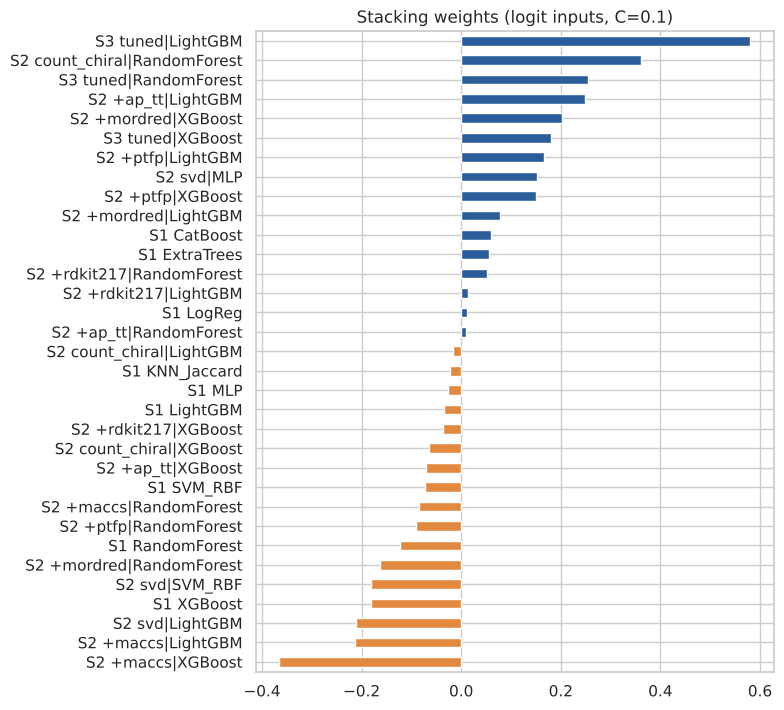

탐욕적 선택(개발 세트 전체, 반복0) 구성: {'2차:count_chiral|RandomForest': 3, '3차:tuned|XGBoost': 3, '3차:tuned|RandomForest': 3, '2차:+mordred|XGBoost': 2, '2차:+ap_tt|XGBoost': 2, '3차:tuned|LightGBM': 1, '2차:+ap_tt|LightGBM': 1}


In [6]:
# 스태킹(전체 후보)의 가중치: 개발 세트 전체 OOF로 한 번 학습해 해석용으로 본다
names = list(pool)
Z = np.column_stack([logit(np.mean([pool[n]["r0"], pool[n]["r1"]], 0)) for n in names])
lr = LogisticRegression(C=0.1, max_iter=2000).fit(Z, yd)
w = pd.Series(lr.coef_[0], index=names).sort_values()
w.to_csv(RES / "stack_weights.csv")
fig, ax = plt.subplots(figsize=(8, max(4, len(w) * 0.22)))
w.rename(lambda n: n.replace("1차:", "S1 ").replace("2차:", "S2 ").replace("3차:", "S3 ")).plot.barh(ax=ax, color=["#e3893f" if v < 0 else "#2b5d9a" for v in w]); ax.set_title("Stacking weights (logit inputs, C=0.1)")
plt.tight_layout(); plt.savefig(RES / "fig_stack_weights.png", dpi=130); plt.show()

g = m_greedy(top_prob); g("r0", np.ones(len(yd), bool), np.ones(len(yd), bool))
print("탐욕적 선택(개발 세트 전체, 반복0) 구성:", pd.Series(g.last).value_counts().to_dict())

## 5. 최종 방법 확정 (제출 파일에 사용)
- 3절 표에서 F1이 가장 높은 (방법, 임계값 방식)을 고른다.
- 구성(모델·가중치·임계값)은 개발 세트 전체의 OOF(반복 0·1 평균)로 다시 정해 `results/final_method.json`에 저장한다.

In [7]:
best_row = summary.sort_values("F1", ascending=False).iloc[0]
METHOD, THR_MODE = best_row["방법"], best_row["임계값"]
p_avg = {n: np.mean([pool[n]["r0"], pool[n]["r1"]], 0) for n in pool}
if METHOD.startswith("단일"):
    kind, names, weights, C = "mean", [BEST], [1.0], None
elif METHOD.startswith("평균"):
    kind, names, weights, C = "mean", tuned, [1 / len(tuned)] * len(tuned), None
elif METHOD.startswith("탐욕"):
    g = m_greedy(top_prob)
    for n in top_prob: pool[n]["avg"] = p_avg[n]
    g("avg", np.ones(len(yd), bool), np.ones(len(yd), bool))
    vc_ = pd.Series(g.last).value_counts(); kind, names, weights, C = "mean", list(vc_.index), list(vc_.values / vc_.sum()), None
else:
    names = tuned if "3개" in METHOD else list(pool); C = 1.0 if "3개" in METHOD else 0.1; kind, weights = "stack", None
if kind == "mean":
    p_full = np.sum([w * p_avg[n] for n, w in zip(names, weights)], 0)
else:
    Zs = np.vstack([np.column_stack([logit(pool[n][r]) for n in names]) for r in ("r0", "r1")])
    lr_f = LogisticRegression(C=C, max_iter=2000).fit(Zs, np.concatenate([yd, yd]))
    p_full = lr_f.predict_proba(np.column_stack([logit(p_avg[n]) for n in names]))[:, 1]
    weights = list(lr_f.coef_[0]); json_intercept = float(lr_f.intercept_[0])
thr = float(best_thr(yd, p_full)) if THR_MODE == "fold 안 임계값" else 0.5
final = {"method": METHOD, "threshold_mode": THR_MODE, "kind": kind, "models": names,
         "weights": [float(w) for w in weights], "C": C, "threshold": thr, "cv_f1": float(best_row["F1"])}
if kind == "stack": final["intercept"] = json_intercept
json.dump(final, open(RES / "final_method.json", "w"), ensure_ascii=False, indent=1)
print(json.dumps({k: v for k, v in final.items() if k not in ("weights",)}, ensure_ascii=False, indent=1))

{
 "method": "스태킹: 전체 후보",
 "threshold_mode": "fold 안 임계값",
 "kind": "stack",
 "models": [
  "1차:LogReg",
  "1차:SVM_RBF",
  "1차:KNN_Jaccard",
  "1차:RandomForest",
  "1차:ExtraTrees",
  "1차:LightGBM",
  "1차:XGBoost",
  "1차:CatBoost",
  "1차:MLP",
  "2차:+rdkit217|RandomForest",
  "2차:+rdkit217|LightGBM",
  "2차:+rdkit217|XGBoost",
  "2차:+mordred|RandomForest",
  "2차:+mordred|LightGBM",
  "2차:+mordred|XGBoost",
  "2차:+ptfp|RandomForest",
  "2차:+ptfp|LightGBM",
  "2차:+ptfp|XGBoost",
  "2차:+maccs|RandomForest",
  "2차:+maccs|LightGBM",
  "2차:+maccs|XGBoost",
  "2차:+ap_tt|RandomForest",
  "2차:+ap_tt|LightGBM",
  "2차:+ap_tt|XGBoost",
  "2차:count_chiral|RandomForest",
  "2차:count_chiral|LightGBM",
  "2차:count_chiral|XGBoost",
  "2차:svd|SVM_RBF",
  "2차:svd|MLP",
  "2차:svd|LightGBM",
  "3차:tuned|LightGBM",
  "3차:tuned|XGBoost",
  "3차:tuned|RandomForest"
 ],
 "C": 0.1,
 "threshold": 0.43,
 "cv_f1": 0.8281695588773657,
 "intercept": -0.010870133312503642
}


## 6. 결론과 마지막 차수로 넘길 것

### 판단
1. 최종 방법은 스태킹 33개 + 임계값 0.43이다. CV F1 0.8282로 지금까지 가장 높다. 기준보다 +0.006이고 10 fold 중 8번 더 좋았다. p = 0.08이라 통계적으로 확정할 수준은 아니지만, 모든 앙상블 방법이 기준보다 높게 나와 방향은 일관된다.
2. 임계값 조정은 단일 모델에서는 효과가 없었다(−0.0007). 반대로 앙상블에서는 +0.002~0.005로 효과가 있었다. 여러 모델을 섞으면 확률이 더 잘 보정돼서, 임계값을 옮겼을 때 이득이 생긴 것으로 보인다.
3. 스태킹 가중치(`fig_stack_weights.png`)와 탐욕적 선택 구성을 보면, 튜닝된 3차 모델과 함께 2차의 입체 count FP·Mordred·AP/TT 모델이 쓰였다. 2차에서 단독으로는 효과가 없던 입력 표현이 앙상블 재료로는 쓸모가 있었다. 음수 가중치는 그 모델이 나쁘다는 뜻이 아니다. 거의 같은 예측을 하는 모델들이 함께 들어가 있어서(상관 0.94~0.99), 스태킹이 중복분을 서로 상쇄한 결과다. 그래서 가중치 하나하나보다 전체 조합의 점수로 판단한다. 그래프의 S1·S2·S3은 1·2·3차를 뜻한다.
4. 1차 RandomForest 0.8177에서 시작해 2차(표현) +0.001, 3차(튜닝) +0.004, 4차(앙상블·임계값) +0.006으로 총 +0.011 올랐다.

### 한계와 다음에 해볼 것
- 구조가 거의 같은 화합물끼리도 라벨 일치율이 0.81이라, 지금 특성으로는 F1 0.83 근처가 한계에 가깝다.
- 더 올리려면 다른 종류의 모델이 필요하다. 그래프 신경망(GNN)이나 사전학습 분자 언어모델(ChemBERTa 등)처럼 SMILES 구조를 직접 학습하는 모델을 앙상블에 더하는 것이 가장 유망하다.

### 제출 파일
- `predict_output_임채현_4차.csv`: 스태킹 33개 + 임계값 0.43. 구성 모델 33개를 8,000행 전체로 재학습하고, 개발 세트 OOF로 학습한 스태킹 가중치를 적용했다. 테스트 세트(1,600행) F1 0.822, AUC 0.880으로 1~3차 중 가장 높다(1차 0.813, 2차 0.821, 3차 0.809). 임계값을 0.43으로 낮춰 Recall 0.872, Precision 0.778이며, 927행 중 비독성 예측 비율은 0.599다.